In [46]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display, Markdown


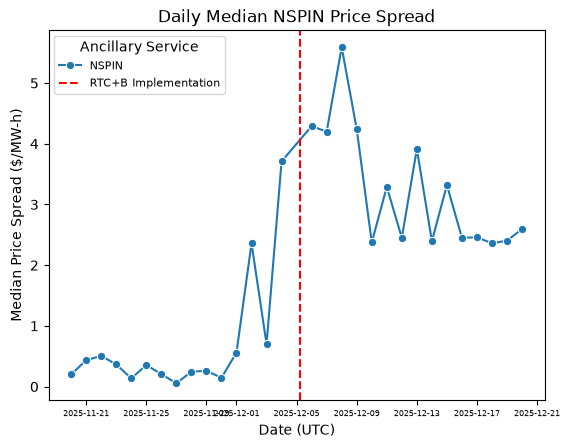

NSPIN experienced the most noticeable change in price spreads following the implementation of RTC+B on December 5, 2025. Before implementation, the median of the daily median spreads was around $0.36, compared to $2.60 afterward. During the pre-RTC+B period, spreads generally remained relatively low, with occasional increases, particularly around December 2. Following implementation, spreads increased substantially and remained consistently elevated throughout the year. The highest daily median spread after implementation occurred on December 8, reaching around $5.59. Although spreads gradually declined afterward, they remained higher than most of the pre-implementation observations. This suggests that NSPIN became more expensive relative to the lowest-priced ancillary service following RTC+B.

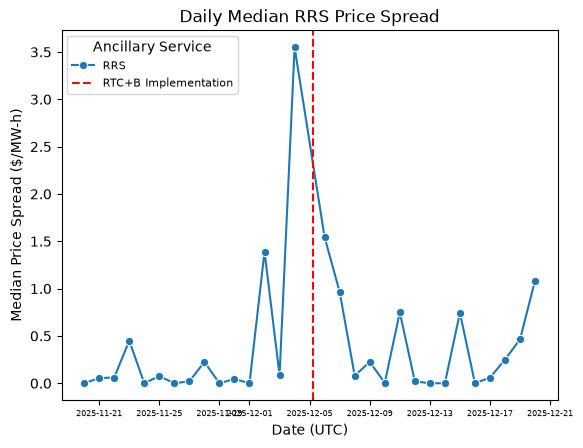

RRS demonstrated a less consistent change following RTC+B implementation. Before implementation, the median of its daily median spreads was around $0.06, increasing to around $0.23 afterward. Unlike NSPIN, RRS experienced several periods of very low or zero spreads both before and after RTC+B. Before implementation, there was a noticeable increase around December 2, followed by a larger spike on December 4, although the latter represents only a partial UTC day. After implementation, the largest daily median spread occurred on December 6 at around $1.54, with additional smaller increases throughout the period. Overall, RRS showed a small increase in its typical daily spread, but the ongoing fluctuations suggest that the impact on its relative pricing was less pronounced than for NSPIN.

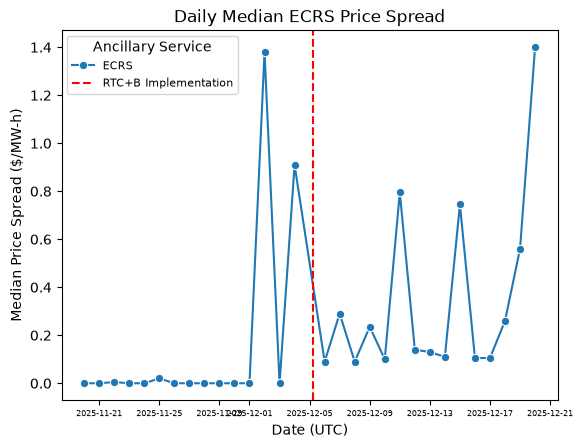

ECRS also experienced a change in its price spreads following RTC+B, although the increase was considerably smaller than that observed for NSPIN. Before implementation, the median of its daily median spreads was $0.00, indicating that ECRS was frequently the lowest-priced ancillary service during the observed hours. Following implementation, this increased to approximately $0.14. ECRS spreads became more consistently positive after RTC+B, with noticeable increases on December 11, 15, and 19. Despite these increases, ECRS generally maintained relatively low price differences compared with NSPIN. This suggests that ECRS prices moved somewhat farther from the lowest ancillary service price after implementation, but the overall change remained relatively limited.

In [47]:
# /Users/jamesmarge/Documents/ArtifexF26/artifex-quarto
ercot = pd.read_csv("../data/ercot_mcpc_comparison.csv")

ercot["time_utc"] = pd.to_datetime(
    ercot["interval_start_utc"],
    utc=True
)

nspin = (
    ercot
    .query("year == 2025")
    .assign(
        spread=lambda x: x["mcpc"] -
        x.groupby("time_utc")["mcpc"].transform("min"),
        date=lambda x: x["time_utc"].dt.floor("D"),
    )
    .query("as_type == 'NSPIN'")
    .groupby(["date", "as_type"], as_index=False)
    .agg(median_spread=("spread", "median"))
)

rrs = (
    ercot
    .query("year == 2025")
    .assign(
        spread=lambda x: x["mcpc"] -
        x.groupby("time_utc")["mcpc"].transform("min"),
        date=lambda x: x["time_utc"].dt.floor("D"),
    )
    .query("as_type == 'RRS'")
    .groupby(["date", "as_type"], as_index=False)
    .agg(median_spread=("spread", "median"))
)

ecrs = (
    ercot
    .query("year == 2025")
    .assign(
        spread=lambda x: x["mcpc"] -
        x.groupby("time_utc")["mcpc"].transform("min"),
        date=lambda x: x["time_utc"].dt.floor("D"),
    )
    .query("as_type == 'ECRS'")
    .groupby(["date", "as_type"], as_index=False)
    .agg(median_spread=("spread", "median"))
)

nspin_analysis = "NSPIN experienced the most noticeable change in price spreads following the implementation of RTC+B on December 5, 2025. Before implementation, the median of the daily median spreads was around $0.36, compared to $2.60 afterward. During the pre-RTC+B period, spreads generally remained relatively low, with occasional increases, particularly around December 2. Following implementation, spreads increased substantially and remained consistently elevated throughout the year. The highest daily median spread after implementation occurred on December 8, reaching around $5.59. Although spreads gradually declined afterward, they remained higher than most of the pre-implementation observations. This suggests that NSPIN became more expensive relative to the lowest-priced ancillary service following RTC+B."
rrs_analysis = "RRS demonstrated a less consistent change following RTC+B implementation. Before implementation, the median of its daily median spreads was around $0.06, increasing to around $0.23 afterward. Unlike NSPIN, RRS experienced several periods of very low or zero spreads both before and after RTC+B. Before implementation, there was a noticeable increase around December 2, followed by a larger spike on December 4, although the latter represents only a partial UTC day. After implementation, the largest daily median spread occurred on December 6 at around $1.54, with additional smaller increases throughout the period. Overall, RRS showed a small increase in its typical daily spread, but the ongoing fluctuations suggest that the impact on its relative pricing was less pronounced than for NSPIN."
ecrs_analysis = "ECRS also experienced a change in its price spreads following RTC+B, although the increase was considerably smaller than that observed for NSPIN. Before implementation, the median of its daily median spreads was $0.00, indicating that ECRS was frequently the lowest-priced ancillary service during the observed hours. Following implementation, this increased to approximately $0.14. ECRS spreads became more consistently positive after RTC+B, with noticeable increases on December 11, 15, and 19. Despite these increases, ECRS generally maintained relatively low price differences compared with NSPIN. This suggests that ECRS prices moved somewhat farther from the lowest ancillary service price after implementation, but the overall change remained relatively limited."

ancillary_type = [
    (nspin, "nspin", nspin_analysis),
    (rrs, "rrs", rrs_analysis),
    (ecrs, "ecrs", ecrs_analysis)
]

def make_graph(ancillary_type, name):
    ax = sns.lineplot(
        data=name,
        x="date",
        y="median_spread",
        hue="as_type",
        dashes=False,
        marker="o"
    )

    ax.axvline(
        pd.Timestamp("2025-12-05 06:00:00+00:00"),
        color="red",
        linestyle="--",
        label="RTC+B Implementation",
    )

    ax.tick_params(axis="x", labelsize=6)
    ax.legend(title="Ancillary Service",
    loc="upper left",
    fontsize=8,
    title_fontsize=10
    )

    ax.set(
        title="Daily Median NSPIN Price Spread",
        xlabel="Date (UTC)",
        ylabel="Median Price Spread ($/MW-h)",
    )

for data, name, analysis in ancillary_type:
    fig = plt.figure()

    make_graph(name, data)
    plt.gca().set_title(f"Daily Median {name.upper()} Price Spread")

    display(fig)
    plt.close(fig)
    
    display(Markdown(analysis))

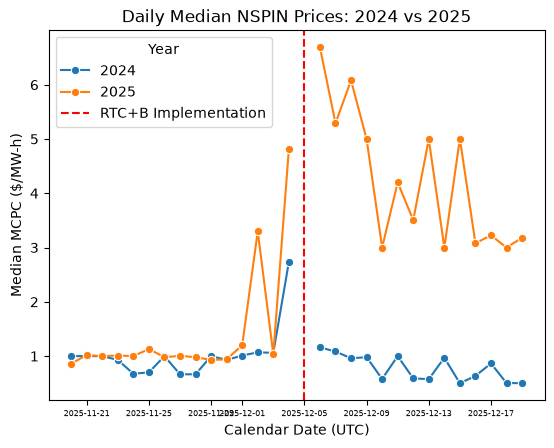

In [48]:
ercot["time_utc"] = pd.to_datetime(
    ercot["interval_start_utc"],
    utc=True
)

ercot_spreads = (
    ercot
    .query("as_type == 'NSPIN'")
    .assign(date=lambda x: x["time_utc"].dt.floor("D"))
    .groupby(["date", "year","window"], as_index=False)
    .agg(
        median_price=("mcpc", "median")
    )
    .assign(
        plot_date=lambda x: pd.to_datetime(
            "2025-" + x["date"].dt.strftime("%m-%d")
        ),
        year=lambda x: x["year"].astype(str)
    )
    .query("'2025-11-20' <= plot_date <= '2025-12-19'")
)

ax = sns.lineplot(
    data=ercot_spreads,
    x="plot_date",
    y="median_price",
    hue="year",
    units="window",
    estimator=None,
    marker="o"
)

ax.axvline(
    pd.Timestamp("2025-12-05"),
    color="red",
    linestyle="--",
    label="RTC+B Implementation"
)

ax.set(
    title="Daily Median NSPIN Prices: 2024 vs 2025",
    xlabel="Calendar Date (UTC)",
    ylabel="Median MCPC ($/MW-h)"
)

ax.legend(title="Year")
ax.tick_params(axis="x", labelsize=6)



<Axes: xlabel='mday', ylabel='median_price'>

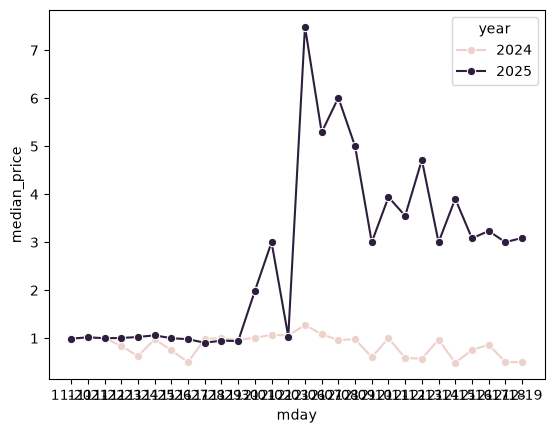

In [50]:
ercot["interval_start_local"] = pd.to_datetime(ercot["interval_start_local"])

nspin_med = (
    ercot
    .query("as_type == 'NSPIN'")
    .assign(mday = lambda x: x["interval_start_local"].dt.strftime("%m-%d"))
    .groupby(["mday", "year"], as_index=False)
    .agg(median_price=("mcpc", "median"))
)

sns.lineplot(
    data=nspin_med,
    x="mday",
    y="median_price",
    hue="year",
    marker="o"
)